# Create card strength model

1. Load card strength dataset
2. Exclude most most recent set (or recent two)
3. Split data
4. Train regressor
   1. XGBoost regression
   2. MLP Regressor
   3. Combine in ensemble
5. Evaluate model
6. Export model

- try log scale for potential decks
- plot prediction error for card types, num colors, ... to find error patterns
- investigate worst predictions to see what the model struggles with
- remove scaler from mlp (since only embedding features)
- try pca features of embeddings for xgboost
- try different language encoders
- label legendary creatures either by inclusion rate or commander play rate
- add rarity feature und is land
- calculate bracket weighted play rate (for both cards in the 99 and commander) \
for each card: calculate play rate per bracket -> weight them $(1 * play-rate(bracket1) + 2 * play-rate(bracket2) + ... ) / 15$

In [109]:
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor

In [110]:
INPUT_DATA_PATH = "data/card_strength_dataset.parquet"
OUTPUT_MODEL_PATH = "card_strength_model.pth"
SEED = 1893

## 1. Load data

In [111]:
np.random.seed(SEED)

df = pd.read_parquet(INPUT_DATA_PATH)

print(f"shape: {df.shape}")
df.head()

shape: (29616, 421)


,oracle_id,name,card_faces,mana_cost,cmc,type_line,oracle_text,power,toughness,loyalty,...,embed_374,embed_375,embed_376,embed_377,embed_378,embed_379,embed_380,embed_381,embed_382,embed_383
0,00037840-6089-42ec-8c5c-281f9f474504,"Nissa, Worldsoul Speaker",None,{3}{G},4.0,Legendary Creature — Elf Druid,"Landfall — Whenever a land you control enters,...",3,3,None,...,0.003654,-0.058060,-0.018109,-0.076759,-0.038501,-0.008318,0.107683,-0.074207,-0.014109,-0.002006
1,0004ebd0-dfd6-4276-b4a6-de0003e94237,Static Orb,None,{3},3.0,Artifact,"As long as this artifact is untapped, players ...",None,None,None,...,-0.001751,0.052983,0.087868,0.063569,0.001657,0.011291,0.153920,-0.002980,-0.018954,-0.011026
2,0006faf6-7a61-426c-9034-579f2cfcfa83,Sensory Deprivation,None,{U},1.0,Enchantment — Aura,Enchant creature\nEnchanted creature gets -3/-0.,None,None,None,...,-0.068337,-0.067909,-0.011745,0.002465,-0.077619,-0.025409,0.030778,-0.003845,0.037397,0.076559
3,0007c283-5b7a-4c00-9ca1-b455c8dff8c3,Road of Return,None,{G}{G},2.0,Sorcery,Choose one —\n• Return target permanent card f...,None,None,None,...,0.014060,0.074960,0.075978,-0.007233,-0.038800,-0.031104,0.037562,0.006684,0.010639,0.039962
4,000d5588-5a4c-434e-988d-396632ade42c,Storm Crow,None,{1}{U},2.0,Creature — Bird,Flying (This creature can't be blocked except ...,1,2,None,...,-0.057929,0.053546,-0.009283,-0.054731,0.004471,-0.041504,0.098369,-0.026667,0.017362,0.051665


In [112]:
embedding_cols = [col for col in df.columns if col.startswith('embed_')]
embedding_features = df[embedding_cols].values

boolean_cols = [col for col in df.columns if col.startswith('bool_')]
boolean_features = df[boolean_cols].values

numerical_cols = [col for col in df.columns if col.startswith('num_')]
numerical_features = df[numerical_cols].fillna(-999).values

feature_names = embedding_cols + numerical_cols + boolean_cols

X = np.hstack((embedding_features, numerical_features, boolean_features))
y = df['log10_power_score'].values

print(f"Final Feature Matrix (X) ready! Shape: {X.shape}")
print(f"Target Variable (y) ready! Shape: {y.shape}")
print(f"Features mapped: {len(embedding_cols)} embedding, {len(numerical_cols)} numerical, {len(boolean_cols)} boolean")

Final Feature Matrix (X) ready! Shape: (29616, 400)
Target Variable (y) ready! Shape: (29616,)
Features mapped: 384 embedding, 5 numerical, 11 boolean


### Plot feature correlations with label

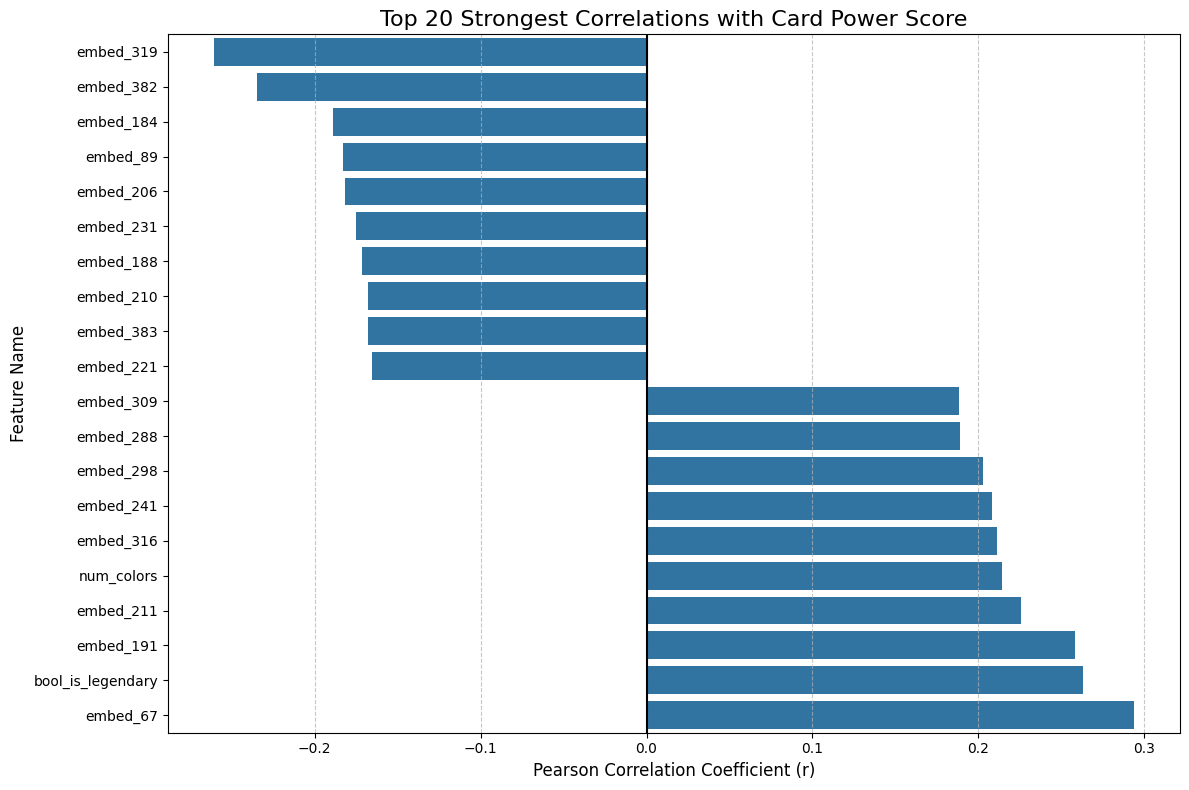

In [113]:
correlations = df[feature_names + ['log10_power_score']].corr()['log10_power_score'].drop('log10_power_score')
top_positive = correlations.nlargest(10)
top_negative = correlations.nsmallest(10)
top_correlations = pd.concat([top_negative, top_positive]).sort_values()

plt.figure(figsize=(12, 8))
sns.barplot(x=top_correlations.values, y=top_correlations.index)
plt.title('Top 20 Strongest Correlations with Card Power Score', fontsize=16)
plt.xlabel('Pearson Correlation Coefficient (r)', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.axvline(x=0, color='black', linestyle='-', linewidth=1.5)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 2. Exclude most recent set

In [114]:
# TODO:

## 3. Split data

In [115]:
# test split
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)

# train and validation split
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=SEED)

print(f"Training data:   {X_train.shape[0]} cards")
print(f"Validation data: {X_val.shape[0]} cards")
print(f"Testing data:    {X_test.shape[0]} cards")

Training data:   17769 cards
Validation data: 5923 cards
Testing data:    5924 cards


## 4. Train regressor

### XGBoost Baseline

In [116]:
baseline_model = xgb.XGBRegressor(random_state=SEED, n_jobs=-1)
baseline_model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=100
)

y_xgbr_preds = baseline_model.predict(X_test)
mae_xgbr = mean_absolute_error(y_test, y_xgbr_preds)
rmse_xgbr = np.sqrt(mean_squared_error(y_test, y_xgbr_preds))

print("--- BASELINE EVALUATION ---")
print(f"Mean Absolute Error (MAE): {mae_xgbr:.3f} points")
print(f"Root Mean Squared Error (RMSE): {rmse_xgbr:.3f} points")

[0]	validation_0-rmse:9.20377	validation_1-rmse:9.13015
[99]	validation_0-rmse:3.04634	validation_1-rmse:7.43283
--- BASELINE EVALUATION ---
Mean Absolute Error (MAE): 5.961 points
Root Mean Squared Error (RMSE): 7.571 points


### Tune XGBoost regressor

In [117]:
xgbr_tuned = xgb.XGBRegressor(
    n_estimators=3000,          # max num of trees
    learning_rate=0.03,         # low learning rate
    max_depth=4,                # Shallow dept to enforce regularization
    subsample=0.8,              # Subset of training data per tree
    colsample_bytree=0.6,       # Subset of features per tree
    min_child_weight=3,
    gamma=0.5,
    early_stopping_rounds=50,

    random_state=SEED,
    n_jobs=-1
)

xgbr_tuned.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=100
)

y_xgbr_preds = xgbr_tuned.predict(X_test)
mae_xgbr = mean_absolute_error(y_test, y_xgbr_preds)
rmse_xgbr = np.sqrt(mean_squared_error(y_test, y_xgbr_preds))

print("\n--- XGBoost TEST EVALUATION ---")
print(f"Mean Absolute Error (MAE): {mae_xgbr:.3f} points")
print(f"Root Mean Squared Error (RMSE): {rmse_xgbr:.3f} points")

[0]	validation_0-rmse:9.84156	validation_1-rmse:9.65833
[100]	validation_0-rmse:7.92103	validation_1-rmse:8.05003
[200]	validation_0-rmse:7.32232	validation_1-rmse:7.69329
[300]	validation_0-rmse:6.92265	validation_1-rmse:7.51397
[400]	validation_0-rmse:6.61677	validation_1-rmse:7.39375
[500]	validation_0-rmse:6.36100	validation_1-rmse:7.30762
[600]	validation_0-rmse:6.13138	validation_1-rmse:7.24262
[700]	validation_0-rmse:5.92861	validation_1-rmse:7.19042
[800]	validation_0-rmse:5.73648	validation_1-rmse:7.14959
[900]	validation_0-rmse:5.55831	validation_1-rmse:7.11540
[1000]	validation_0-rmse:5.39626	validation_1-rmse:7.08655
[1100]	validation_0-rmse:5.23719	validation_1-rmse:7.05993
[1200]	validation_0-rmse:5.09099	validation_1-rmse:7.03239
[1300]	validation_0-rmse:4.94862	validation_1-rmse:7.01330
[1400]	validation_0-rmse:4.81091	validation_1-rmse:6.99322
[1500]	validation_0-rmse:4.68744	validation_1-rmse:6.97574
[1600]	validation_0-rmse:4.57219	validation_1-rmse:6.96234
[1700]	va

### XGBoost feature importance

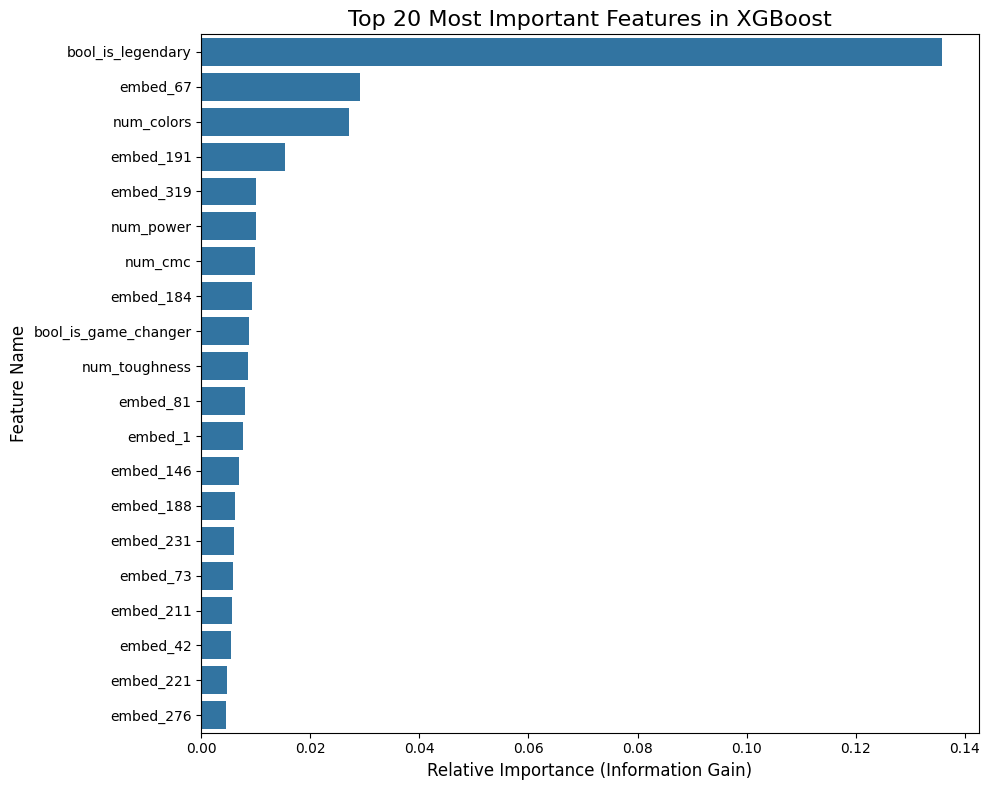

In [118]:
importances = xgbr_tuned.feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(20))
plt.title('Top 20 Most Important Features in XGBoost', fontsize=16)
plt.xlabel('Relative Importance (Information Gain)', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.tight_layout()
plt.show()

### Train MLP regressor

In [119]:
# only use embedding features for MLP
num_embeds = len(embedding_cols)
X_train_mlp = X_train_val[:, :num_embeds]
X_test_mlp  = X_test[:, :num_embeds]

# scale MLP features
scaler = StandardScaler()
X_train_mlp_scaled = scaler.fit_transform(X_train_mlp)
X_test_mlp_scaled = scaler.transform(X_test_mlp)

### Train MLP Baseline

In [120]:
mlp_baseline = MLPRegressor(random_state=SEED)
mlp_baseline.fit(X_train_mlp_scaled, y_train_val)

mlp_baseline_preds = mlp_baseline.predict(X_test_mlp_scaled)
mlp_baseline_mae = mean_absolute_error(y_test, mlp_baseline_preds)
mlp_baseline_rmse = np.sqrt(mean_squared_error(y_test, mlp_baseline_preds))

print("\n--- MLP BASELINE EVALUATION ---")
print(f"MAE: {mlp_baseline_mae:.3f} points")
print(f"RMSE: {mlp_baseline_rmse:.3f} points")


--- MLP BASELINE EVALUATION ---
MAE: 6.388 points
RMSE: 8.175 points


C:\Users\ruflu\AppData\Roaming\Python\Python312\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


### Tune MLP Regressor

In [121]:
mlp_tuned = MLPRegressor(
    hidden_layer_sizes=(512, 256, 64),
    activation='relu',
    solver='adam',
    alpha=0.5, # L2 regularization
    learning_rate_init=0.0005,

    batch_size=256,
    validation_fraction=0.2,

    max_iter=200,
    early_stopping=True,
    n_iter_no_change=20,
    
    random_state=SEED,
    verbose=True
)

mlp_tuned.fit(X_train_mlp_scaled, y_train_val)

y_mlp_preds = mlp_tuned.predict(X_test_mlp_scaled)
mlp_tuned_mae = mean_absolute_error(y_test, y_mlp_preds)
mlp_tuned_rmse = np.sqrt(mean_squared_error(y_test, y_mlp_preds))

print("\n--- TUNED MLP TEST EVALUATION ---")
print(f"MAE: {mlp_tuned_mae:.3f} points")
print(f"RMSE: {mlp_tuned_rmse:.3f} points")

Iteration 1, loss = 520.31626102
Validation score: 0.221647
Iteration 2, loss = 32.13959996
Validation score: 0.375779
Iteration 3, loss = 27.53449892
Validation score: 0.405639
Iteration 4, loss = 25.19600886
Validation score: 0.432710
Iteration 5, loss = 23.16886950
Validation score: 0.448147
Iteration 6, loss = 21.96208593
Validation score: 0.459452
Iteration 7, loss = 20.71232726
Validation score: 0.466485
Iteration 8, loss = 19.59551419
Validation score: 0.474537
Iteration 9, loss = 18.88450540
Validation score: 0.474491
Iteration 10, loss = 18.38602917
Validation score: 0.476092
Iteration 11, loss = 17.41604214
Validation score: 0.480971
Iteration 12, loss = 16.92098115
Validation score: 0.487986
Iteration 13, loss = 16.12730420
Validation score: 0.494097
Iteration 14, loss = 16.05445623
Validation score: 0.488199
Iteration 15, loss = 15.20044862
Validation score: 0.487154
Iteration 16, loss = 14.77442452
Validation score: 0.494211
Iteration 17, loss = 14.28117190
Validation scor

### Combine into ensemble regressor

_Might need to modify for cards that do not have any oracle text_

In [122]:
# A simple 50/50 weighted average of both models
ensemble_preds = (y_xgbr_preds + y_mlp_preds) / 2.0

ensemble_mae = mean_absolute_error(y_test, ensemble_preds)
ensemble_rmse = np.sqrt(mean_squared_error(y_test, ensemble_preds))

print("\n--- ENSEMBLE TEST EVALUATION ---")
print(f"Ensemble MAE: {ensemble_mae:.3f} points")
print(f"Ensemble RMSE: {ensemble_rmse:.3f} points")


--- ENSEMBLE TEST EVALUATION ---
Ensemble MAE: 5.266 points
Ensemble RMSE: 6.692 points


### Ensemble test performance plot

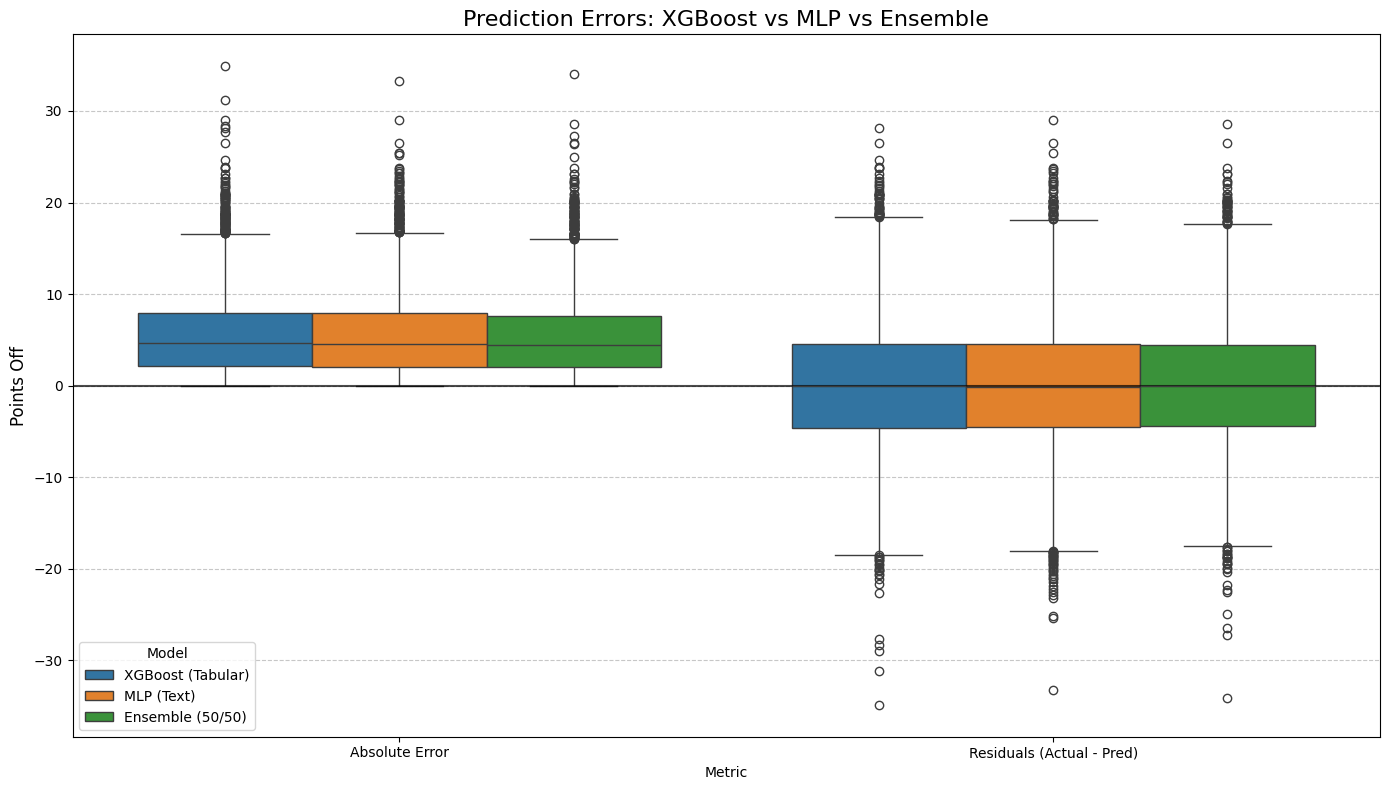

In [ ]:
def append_data(errors, model_name, metric_name):
    for err in errors:
        plot_data.append({'Model': model_name, 'Metric': metric_name, 'Error (Points)': err})

# calculate absolute error
abs_err_xgb = np.abs(y_test - y_xgbr_preds)
abs_err_mlp = np.abs(y_test - y_mlp_preds)
abs_err_ens = np.abs(y_test - ensemble_preds)

# calculate residuals
res_xgb = y_test - y_xgbr_preds
res_mlp = y_test - y_mlp_preds
res_ens = y_test - ensemble_preds

plot_data = []
append_data(abs_err_xgb, 'XGBoost (Tabular)', 'Absolute Error')
append_data(abs_err_mlp, 'MLP (Text)', 'Absolute Error')
append_data(abs_err_ens, 'Ensemble (50/50)', 'Absolute Error')
append_data(res_xgb, 'XGBoost (Tabular)', 'Residuals (Actual - Pred)')
append_data(res_mlp, 'MLP (Text)', 'Residuals (Actual - Pred)')
append_data(res_ens, 'Ensemble (50/50)', 'Residuals (Actual - Pred)')

error_df = pd.DataFrame(plot_data)

plt.figure(figsize=(14, 8))
sns.boxplot(x='Metric', y='Error (Points)', hue='Model', data=error_df)
plt.title('Prediction Errors: XGBoost vs MLP vs Ensemble', fontsize=16)
plt.ylabel('Points Off', fontsize=12)
plt.axhline(y=0, color='black', linestyle='-', linewidth=1.5, alpha=0.7)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Try adaptive ensemble

In [125]:
dynamic_ensemble_preds = np.zeros_like(y_test)
threshold = 10.0  # Point difference required to trigger the "Trust the Text" rule

for i in range(len(y_test)):
    xgb_pred = y_xgbr_preds[i]
    mlp_pred = y_mlp_preds[i]
    
    # # RULE 1: Vanilla Cards (Blind MLP)
    # if bool_is_vanilla_test[i]:
    #     dynamic_ensemble_preds[i] = xgb_pred
        
    # # RULE 2: Keyword-Only Cards (French Vanilla)
    # elif bool_is_keyword_only_test[i]:
    #     dynamic_ensemble_preds[i] = (0.75 * xgb_pred) + (0.25 * mlp_pred)
        
    # RULE 3: Violent Disagreement (The "Trust the Text" rule)
    # If the models disagree by more than 10 points, the text is the anomaly.
    # elif abs(mlp_pred - xgb_pred) > threshold:
    if abs(mlp_pred - xgb_pred) > threshold:
        dynamic_ensemble_preds[i] = (0.75 * mlp_pred) + (0.25 * xgb_pred)
        
    # RULE 4: Standard Cards
    else:
        dynamic_ensemble_preds[i] = (0.5 * xgb_pred) + (0.5 * mlp_pred)

dynamic_mae = mean_absolute_error(y_test, dynamic_ensemble_preds)
dynamic_rmse = np.sqrt(mean_squared_error(y_test, dynamic_ensemble_preds))

print("\n--- ADAPTIVE ENSEMBLE EVALUATION ---")
print(f"MAE:  {dynamic_mae:.3f} points")
print(f"RMSE: {dynamic_rmse:.3f} points")


--- ADAPTIVE ENSEMBLE EVALUATION ---
MAE:  5.271 points
RMSE: 6.698 points
